<a href="https://colab.research.google.com/github/Andru-1987/data_science_ii_96085/blob/main/12_semana/clase_practica/clase_practica_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Airbnb Buenos Aires: de un analisis simple a una segmentacion por capas

Resumen de todo el recorrido en cuatro partes, cada una con su conclusion:

| Parte | Que se hace | Pregunta que responde |
|---|---|---|
| 1 | Analisis simple + K-means | Como se ve el mercado y que perfiles aparecen? |
| 2 | K-means vs HDBSCAN | Los grupos son naturales o el mercado es un continuo? |
| 3 | Reglas de negocio (capa 1) + K-means vs Gaussian Mixture (capa 2) | Se puede segmentar mejor separando primero lo evidente? |
| 4 | Conclusiones finales | Que decimos del mercado y que metodo usar? |

Dataset: Inside Airbnb Buenos Aires, precios en ARS.

| Columna | Qué es | Notas y uso en el análisis |
|---|---|---|
| `id` | Identificador único del aviso | Solo identificador, no se usa como variable |
| `name` | Título del aviso | Texto libre, no se usó |
| `host_id` | Identificador del anfitrión | Sirve para agrupar avisos por host (por ejemplo, auditar a los profesionales) |
| `host_profile_id` | Identificador del perfil del anfitrión | Identificador, no se usó |
| `host_name` | Nombre del anfitrión | No se usó |
| `neighbourhood_group` | Agrupación de barrios | 100% nulo, se descartó |
| `neighbourhood` | Barrio del aviso | Se usó para KPIs y para calcular `precio_rel` (precio contra pares del mismo barrio) |
| `latitude`, `longitude` | Coordenadas del aviso | Se usaron para calcular `dist_centro_km`, la distancia al Obelisco |
| `room_type` | Tipo de alojamiento: departamento entero, habitación privada, compartida o de hotel | 90% son departamentos enteros. Se usó en el perfilado y en `precio_rel` |
| `price` | Precio por noche en ARS | 7% nulo (esas filas se eliminaron). Tiene outliers extremos, hasta ARS 160M, por eso se winsorizó entre p1 y p99 |
| `minimum_nights` | Mínimo de noches por reserva | Base de la regla de estadía larga (30 noches o más) |
| `number_of_reviews` | Cantidad total de reviews históricas | Proxy de antigüedad y demanda acumulada |
| `last_review` | Fecha de la última review | 12% nulo, que significa "nunca tuvo reviews". Se convirtió en días desde la última review |
| `reviews_per_month` | Promedio de reviews por mes | Nulo cuando no hay reviews, se imputó con 0 |
| `calculated_host_listings_count` | Cantidad de avisos que tiene el mismo host | Define "host profesional" (5 o más avisos) |
| `availability_365` | Días disponibles en los próximos 365 | Más bajo suele implicar más ocupación, pero es solo un proxy |
| `number_of_reviews_ltm` | Reviews de los últimos 12 meses (LTM = last twelve months) | Es la mejor señal de demanda reciente. Base de la regla de inactivo (0 reviews LTM) |
| `license` | Licencia o registro de alojamiento | 98% nulo, se descartó |

**Aclaraciones**
- Las reviews son un proxy de demanda, no de ocupación real. No todos los huéspedes dejan reseña.
- No hay ratings, amenities ni capacidad en este dataset. Agregarlos mejoraría la segmentación.
- Las columnas derivadas que creé (`precio_rel`, `dist_centro_km`, `dias_ult_review`, `log_demanda_disp`) no vienen en el CSV original.

---
# PARTE 1. Analisis simple y K-means

## 1.1 Carga y limpieza

Decisiones, con su motivo:
- Se eliminan avisos sin `price` (7%) o sin `minimum_nights`: el precio es la variable central y no se puede inventar.
- El precio se **winsoriza en p1-p99**: hay avisos de hasta ARS 160M que dominarian cualquier distancia.
- `last_review` nulo significa "nunca tuvo reviews": se codifica como 2000 dias de antiguedad.
- Se descartan `neighbourhood_group` y `license` (casi vacias).

In [50]:
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

url:str = "https://raw.githubusercontent.com/Andru-1987/csv_files_ds/refs/heads/main/buenos_aires.csv"

df = pd.read_csv(url)
ref = pd.Timestamp("2026-09-30")
df["last_review"] = pd.to_datetime(df["last_review"])
df = df[df.price.notna() & (df.price > 0) & df.minimum_nights.notna()].copy()

lo, hi = df.price.quantile([.01, .99])
df["price_w"] = df.price.clip(lo, hi)
df["dias_ult_review"] = (ref - df.last_review).dt.days.fillna(2000).clip(upper=2000)
df["sin_reviews"] = (df.number_of_reviews == 0).astype(int)
df["multi_host"] = (df.calculated_host_listings_count >= 5).astype(int)
print("Avisos tras limpieza:", len(df))

Avisos tras limpieza: 27633


In [51]:
df.sample(10)

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,...,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,price_w,dias_ult_review,sin_reviews,multi_host
22482,1516392882336132772,Peatonal Florida. Plaza San Martin. Centrico,100049448,1467202062239058667,Nancy,NaN,Retiro,-34.596969,-58.375074,Entire home/apt,...,2026-09-15,4.76,6,61,55,NaN,67910.0,15.0,0,1
13611,1024718747576035501,Monoambiente divisible Palermo,546515008,1470445946407821903,Romina Paula,NaN,Palermo,-34.595220,-58.415740,Entire home/apt,...,2026-08-21,0.49,1,39,3,NaN,100902.0,40.0,0,0
13029,1001642284839093996,"Stay in Recoleta, Enjoy Style & Comfort",541738672,1463872500194058651,Michel Y Lucrecia,NaN,Recoleta,-34.589866,-58.398647,Entire home/apt,...,2026-09-20,1.45,1,206,20,RL-2025-53560369-GCABA-DGDTU,303470.0,10.0,0,0
21173,1439773207924792865,Lujoso Departamento 3 dormitorios -Nuevo,399571000,1469835759950364363,Live SoHo Boutique Apartments,NaN,Villa Devoto,-34.597277,-58.502798,Entire home/apt,...,2026-09-09,1.15,24,296,14,NaN,297202.0,21.0,0,1
25668,1638682549374158004,Casa Lima Sur- 6 Camas Mixtas 2piso 2KA,7617724,1521793299811611448,Casa Lima,NaN,Constitucion,-34.619900,-58.381950,Shared room,...,2026-09-25,2.03,10,365,5,NaN,27519.0,5.0,0,1
7969,706429651241792634,"Studio 4 pax, S. pool, Plaza Serrano, La Rural",251130690,1469331051333348851,Walter Hernan,NaN,Palermo,-34.581790,-58.428310,Entire home/apt,...,2026-08-25,2.17,16,354,35,NaN,104447.0,36.0,0,1
8191,728059936064320349,Cálido y Luminoso departamento en Palermo Soho,150919239,1468483296250540981,Gabriel,NaN,Palermo,-34.587820,-58.421680,Entire home/apt,...,2026-08-12,0.75,2,68,5,NaN,115120.0,49.0,0,0
21186,1432707923422671628,Amplio c/balcón,182960400,1468945309650623508,Magali,NaN,Palermo,-34.569070,-58.441570,Entire home/apt,...,2026-09-06,1.92,15,233,22,NaN,148417.0,24.0,0,1
3666,32428966,Depto ideal en Recoleta,76822939,1466941555844387942,Sol,NaN,Recoleta,-34.591790,-58.404840,Entire home/apt,...,2026-09-16,0.57,1,246,8,NaN,134667.0,14.0,0,0
5113,41561411,Edu & Vini's romantic studio in Palermo Soho,12668151,1462892957923459277,Eduardo,NaN,Palermo,-34.588810,-58.423750,Entire home/apt,...,2026-09-21,1.80,1,320,31,NaN,119248.0,9.0,0,0


## 1.2 KPIs simples

Antes de modelar, los KPIs descriptivos cuentan parte de la historia y sirven de referencia para validar los clusters.

In [52]:
print("Avisos de hosts con 5+ propiedades:", f"{df.multi_host.mean():.1%}")
print("Avisos con al menos 1 review en el ultimo anio:", f"{(df.number_of_reviews_ltm > 0).mean():.1%}")

Avisos de hosts con 5+ propiedades: 40.3%
Avisos con al menos 1 review en el ultimo anio: 78.8%


In [53]:
(
    df
    .groupby("room_type")
    .agg(
        n=("id", "size"),
        precio_mediano=("price", "median"),
        reviews_ltm_prom=("number_of_reviews_ltm", "mean")
    )
    .assign(porcentaje=lambda x: (x["n"] / len(df) * 100).round(1))
    .round(1)
    .sort_values("n", ascending=False)
)

,n,precio_mediano,reviews_ltm_prom,porcentaje
room_type,,,,
Entire home/apt,24919,110075.0,14.4,90.2
Private room,2437,52836.0,6.9,8.8
Shared room,151,30577.0,7.7,0.5
Hotel room,126,253615.5,1.2,0.5


In [54]:
b = (df
     .groupby("neighbourhood")
     .agg(
         n=("id", "size"),
         precio_mediano=("price", "median"),
         reviews_ltm_prom=("number_of_reviews_ltm", "mean"))
     .sort_values("n", ascending=False)
    )
b.head()

,n,precio_mediano,reviews_ltm_prom
neighbourhood,,,
Palermo,9052,117494.0,16.047614
Recoleta,3754,113897.0,13.064731
San Nicolas,2283,96316.0,17.762155
Monserrat,1373,93773.0,14.075747
Retiro,1363,107782.0,12.859868


In [55]:
b[b.n >= 800].sort_values("n", ascending=False).round(1)

,n,precio_mediano,reviews_ltm_prom
neighbourhood,,,
Palermo,9052,117494.0,16.0
Recoleta,3754,113897.0,13.1
San Nicolas,2283,96316.0,17.8
Monserrat,1373,93773.0,14.1
Retiro,1363,107782.0,12.9
Belgrano,1313,114662.0,12.3
Balvanera,1118,85881.5,9.3
Almagro,1010,89436.0,9.3
Villa Crespo,961,93258.0,12.9


**Lectura:** el mercado esta muy profesionalizado (40% de los avisos pertenecen a hosts con 5+ propiedades), el 90% son departamentos enteros y hay un 21% de avisos sin actividad en el ultimo anio. Palermo concentra un tercio de la oferta.

## 1.3 Variables, estandarizacion y PCA

**Variables (8):** precio, noches minimas, reviews totales, reviews LTM, reviews por mes, listings del host, disponibilidad y dias desde la ultima review. Las de cola larga se pasan a `log` (o `log1p` si tienen ceros) para acercarlas a una forma simetrica.

**Estandarizacion obligatoria** (`StandardScaler`): sin ella, `disponibilidad` (0-365) dominaria sobre `log_precio` solo por su escala.

**PCA** se usa para **explicar** que ejes ordenan los datos. K-means se corre sobre las 8 variables estandarizadas.

In [56]:
F = pd.DataFrame({
    "log_precio":          np.log(df.price_w),
    "log_min_noches":      np.log(df.minimum_nights),
    "log_reviews_total":   np.log1p(df.number_of_reviews),
    "log_reviews_ltm":     np.log1p(df.number_of_reviews_ltm),
    "log_reviews_mes":     np.log1p(df.reviews_per_month.fillna(0)),
    "log_listings_host":   np.log(df.calculated_host_listings_count),
    "disponibilidad":      df.availability_365,
    "log_dias_ult_review": np.log1p(df.dias_ult_review),
})
X = StandardScaler().fit_transform(F)
pca = PCA().fit(X)
Z = pca.transform(X)
print("Varianza acumulada:", pca.explained_variance_ratio_.cumsum().round(3))
print()
print(pd.DataFrame(pca.components_[:3].T, index=F.columns, columns=["PC1", "PC2", "PC3"]).round(2))

Varianza acumulada: [0.427 0.609 0.725 0.827 0.915 0.957 0.987 1.   ]

                      PC1   PC2   PC3
log_precio           0.05  0.50 -0.64
log_min_noches      -0.22 -0.35  0.28
log_reviews_total    0.46 -0.14 -0.02
log_reviews_ltm      0.52 -0.05  0.05
log_reviews_mes      0.49 -0.02  0.07
log_listings_host    0.05  0.59  0.13
disponibilidad       0.00  0.50  0.69
log_dias_ult_review -0.48  0.06 -0.07


**Lectura de los ejes:** PC1 (43%) es **actividad/demanda** (reviews LTM, mensuales y totales con signo positivo; antiguedad de la ultima review con signo negativo). PC2 (18%) es **profesionalizacion**: listings del host, precio y disponibilidad. Hacen falta 5 componentes para llegar al 91%, asi que un grafico 2D es una vista parcial.

## 1.4 K-means: eleccion de K y clustering

K-means exige definir K. Se evaluan el **metodo del codo** (inercia) y el **silhouette**, y se complementan con criterio de negocio.

 k  inercia  silhouette
 2   153901       0.270
 3   136836       0.170
 4   123169       0.172
 5   111928       0.175
 6   103739       0.174
 7    96355       0.176
 8    91504       0.171


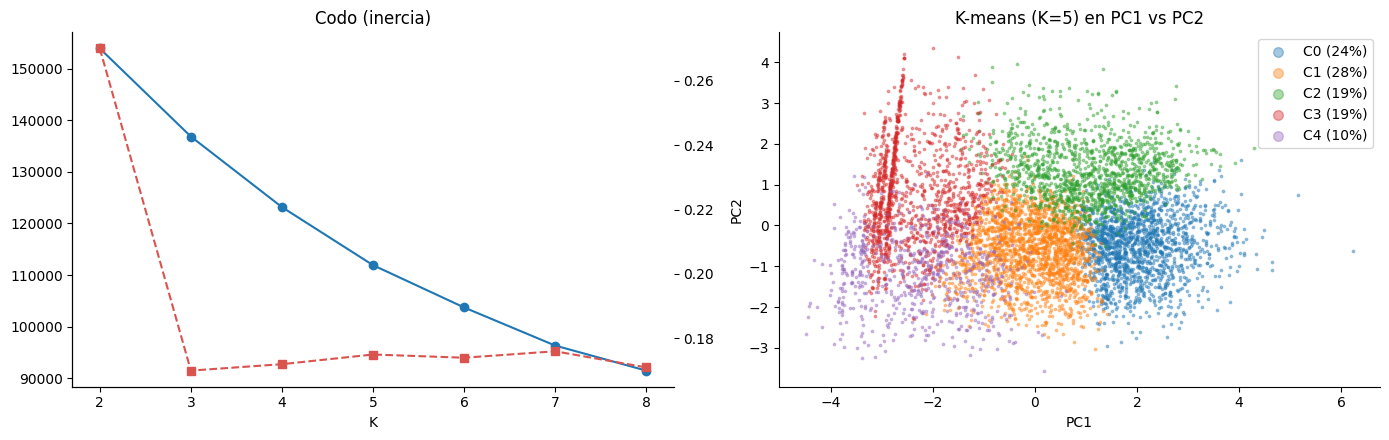

In [57]:
rng = np.random.RandomState(0)
idx = rng.choice(len(X), 8000, replace=False)       # silhouette es O(n^2): se muestrea
res = []
for k in range(2, 9):
    m_ = KMeans(k, n_init=10, random_state=0).fit(X)
    res.append((k, round(m_.inertia_), round(silhouette_score(X[idx], m_.labels_[idx]), 3)))
R1 = pd.DataFrame(res, columns=["k", "inercia", "silhouette"])
print(R1.to_string(index=False))

K1 = 5
km1 = KMeans(K1, n_init=20, random_state=0).fit(X)
df["km1"] = km1.labels_

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(R1.k, R1.inercia, "o-")
ax[0].set_title("Codo (inercia)")
ax[0].set_xlabel("K")
ax[0].twinx().plot(R1.k, R1.silhouette, "s--", c="#d9534f")

for k in range(K1):
    m = km1.labels_ == k
    ax[1].scatter(Z[m, 0][::4], Z[m, 1][::4], s=3, alpha=.4, label=f"C{k} ({m.mean()*100:.0f}%)")

ax[1].legend(markerscale=4)
ax[1].set_title("K-means (K=5) en PC1 vs PC2")
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC2")
plt.tight_layout()
plt.show()

**Decision: K = 5.** El codo no marca un quiebre y el silhouette queda plano en torno a 0,17 para K >= 3 (solo K=2 destaca, pero separaria apenas activos de inactivos, algo poco accionable). K=5 es una eleccion de **negocio**: el silhouette no empeora y los segmentos resultan interpretables.

## 1.5 Perfilado de los clusters

Se leen las medianas en unidades originales para ponerle nombre a cada grupo.

In [58]:
agg = dict(
    n=("id", "size"),
    precio=("price", "median"),
    min_noches=("minimum_nights", "median"),
    reviews_ltm=("number_of_reviews_ltm", "median"),
    listings_host=("calculated_host_listings_count", "median"),
    disp=("availability_365", "median"),
    dias_ult_review=("dias_ult_review", "median"),
    pct_sin_reviews=("sin_reviews", "mean")
)


p1 = (df
      .groupby("km1")
      .agg(**agg))

p1["pct"] = (p1.n / len(df) * 100).round(1)

p1.round(1)


,n,precio,min_noches,reviews_ltm,listings_host,disp,dias_ult_review,pct_sin_reviews,pct
km1,,,,,,,,,
0,6532,101921.0,2.0,29.0,2.0,256.0,15.0,0.0,23.6
1,7789,99373.0,2.0,5.0,2.0,208.0,52.0,0.0,28.2
2,5371,134536.0,2.0,13.0,31.0,337.0,28.0,0.0,19.4
3,5300,119120.0,2.0,0.0,3.0,305.5,2000.0,0.5,19.2
4,2641,68578.0,14.0,0.0,2.0,255.0,509.0,0.2,9.6


In [59]:
nombres1 = {
    0: "Estrellas",
    1: "Activos moderados",
    2: "Operadores profesionales",
    3: "Dormidos o nuevos",
    4: "Estadia larga"
    }

df["km1_nombre"] = df.km1.map(nombres1)
df.km1_nombre.value_counts(normalize=True).round(3)

,proportion
km1_nombre,
Activos moderados,0.282
Estrellas,0.236
Operadores profesionales,0.194
Dormidos o nuevos,0.192
Estadia larga,0.096


### Conclusiones de la Parte 1

- **C0 Estrellas (24%):** 29 reviews LTM, ultima review hace 15 dias, hosts chicos. Son los avisos mas activos.
- **C1 Activos moderados (28%):** actividad media-baja y menor disponibilidad.
- **C2 Operadores profesionales (19%):** hosts con ~31 avisos, disponibilidad 337 y el precio mas alto.
- **C3 Dormidos o nuevos (19%):** casi la mitad sin ninguna review y 0 reviews LTM.
- **C4 Estadia larga (10%):** minimo de 14 noches, precio mas bajo.
- **Hallazgo:** los profesionales (C2) cobran mas que las Estrellas pero logran menos de la mitad de reviews LTM; los hosts chicos activos rinden mas por aviso.
- **Alerta:** el silhouette es bajo (~0,17). Los grupos no son claramente separables, y eso se investiga en la Parte 2.

---
# PARTE 2. K-means vs HDBSCAN: el ruido como señal

K-means obliga a que **todos** los avisos pertenezcan a un grupo y asume grupos esfericos. **HDBSCAN** busca zonas densas, descubre solo la cantidad de clusters y marca como **ruido** (`-1`) lo que no pertenece a ninguna zona densa. Si los grupos fueran naturales, el ruido seria bajo; si el mercado es un continuo, el ruido sera alto.

## 2.1 Sensibilidad a los parametros

- `min_cluster_size`: tamano minimo de un cluster.
- `min_samples`: cuan conservador es el algoritmo (mas alto implica mas ruido).

Se prueba en dos espacios: las 8 variables y los primeros 5 componentes principales (91,5% de varianza), donde la densidad suele estimarse mejor.

In [ ]:
Z5 = Z[:, :5]
rng = np.random.RandomState(0)
rows = []

for nombre, D in [("8 variables", X), ("PCA 5 comp.", Z5)]:
    for mcs, ms in [(200, 10), (200, 20), (300, 30), (500, 50)]:
        l = HDBSCAN(min_cluster_size=mcs, min_samples=ms, copy=True).fit(D).labels_
        m = l != -1; nc = len(set(l)) - (1 if -1 in l else 0)
        s = np.nan
        if nc > 1:
            i = rng.choice(np.where(m)[0], min(6000, m.sum()), replace=False)
            s = silhouette_score(D[i], l[i])
        rows.append((nombre, mcs, ms, nc, round((~m).mean() * 100, 1), round(s, 3)))

print(pd.DataFrame(rows, columns=["espacio", "min_cluster_size", "min_samples", "n_clusters", "ruido_%", "sil_sin_ruido"]).to_string(index=False))

**Lectura:** el porcentaje de ruido va de un tercio a mas del 80% segun los parametros, y no hay punto intermedio donde aparezcan varios clusters con poco ruido. Ademas, el silhouette de HDBSCAN solo mide los puntos **no ruidosos**, asi que no es comparable con el de K-means, que clasifica todo.

Se eligen dos configuraciones para comparar:
- **A:** 8 variables, `min_cluster_size=200`, `min_samples=10` (mismo espacio que K-means).
- **B:** PCA 5 componentes, `min_cluster_size=200`, `min_samples=20`.

## 2.2 Resultados y comparacion

In [ ]:
hA = HDBSCAN(min_cluster_size=200, min_samples=10, copy=True).fit(X)
hB = HDBSCAN(min_cluster_size=200, min_samples=20, copy=True).fit(Z5)
df["hdb_x8"], df["hdb_pca5"] = hA.labels_, hB.labels_

agg2 = dict(n=("id", "size"), precio=("price", "median"), reviews_ltm=("number_of_reviews_ltm", "median"),
            listings_host=("calculated_host_listings_count", "median"), disp=("availability_365", "median"),
            dias_ult_review=("dias_ult_review", "median"), pct_sin_reviews=("sin_reviews", "mean"))
for c in ["hdb_x8", "hdb_pca5"]:
    t = df.groupby(c).agg(**agg2); t["pct"] = (t.n / len(df) * 100).round(1)
    m = df[c] != -1
    print(f"\n== {c}  |  ARI vs K-means (sin ruido): {adjusted_rand_score(df.km1[m], df[c][m]):.3f}")
    print(t.round(2).to_string())
    print("\n\n")

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
def sc(a_, lab, t):
    for c in sorted(set(lab)):
        m = lab == c
        if c == -1: a_.scatter(Z[m, 0][::3], Z[m, 1][::3], s=3, c="lightgray", alpha=.3, label=f"Ruido ({m.mean()*100:.0f}%)")
        else:       a_.scatter(Z[m, 0][::3], Z[m, 1][::3], s=4, alpha=.5, color=plt.cm.tab10(c % 10), label=f"C{c} ({m.mean()*100:.0f}%)")
    a_.legend(markerscale=4, fontsize=8); a_.set_title(t); a_.set_xlabel("PC1"); a_.set_ylabel("PC2")
sc(ax[0], df.km1.values, "K-means (K=5)")
sc(ax[1], df.hdb_x8.values, "HDBSCAN en 8 variables")
sc(ax[2], df.hdb_pca5.values, "HDBSCAN en 5 PCs")
plt.tight_layout()
plt.show()

ct = pd.crosstab(df.km1_nombre, df.hdb_pca5.map(lambda x: "Ruido" if x == -1 else f"H{x}"), normalize="index")
print("\n% de cada cluster K-means dentro de HDBSCAN (PCA 5):"); print(ct.round(2).to_string())

### Conclusiones de la Parte 2

- **El mercado es un continuo.** Con 5 componentes, HDBSCAN deja como ruido el 63% de los avisos; con 8 variables, entre 34% y 82% segun parametros. No hay fronteras de densidad claras.
- **Las dos particiones casi no coinciden** (ARI 0,02 a 0,12). Los 5 segmentos de K-means son cortes utiles pero **de grado, no de naturaleza**: cerca de la mitad de las Estrellas, Activos moderados y Operadores profesionales cae en ruido, y la otra mitad en un mismo nucleo activo.
- **Lo que HDBSCAN si encuentra:** un **nucleo activo** denso (34%: hosts chicos, ~15 reviews LTM) y **tres grupos compactos de avisos muertos** (3,5% en total, 95-99% sin reviews, siempre disponibles). Uno son ~260 avisos de hosts con ~19 propiedades a precio alto: inventario muerto *profesional*, que K-means diluye dentro de "Dormidos".
- **C4 Estadia larga no tiene densidad propia:** casi todo cae en ruido. Es un perfil real pero disperso.
- **Limitacion:** los grupos de avisos muertos son densos en parte por mi imputacion (`dias_ult_review=2000` repite el mismo valor en miles de filas). Deben leerse como "avisos sin actividad", no como poblaciones con estructura propia.
- **Que se aprende:** K-means sirve para comunicar; HDBSCAN sirve para **validar** y para **aislar** el inventario muerto. Segmentar todo el mercado de una vez mezcla poblaciones muy distintas, y de ahi surge la Parte 3.

---
# PARTE 3. Mejora: reglas de negocio (capa 1) + K-means vs Gaussian Mixture (capa 2)

La Parte 2 mostro que los avisos muertos y el resto son poblaciones distintas. En lugar de pedirle a un algoritmo que lo descubra, se **separan primero con reglas explicables** y se clusteriza solo lo que compite en el mercado.

## 3.1 Capa 1: reglas de negocio

Se aplican **en orden de prioridad**: un aviso cae en la primera regla que cumple.

| Orden | Regla | Condicion | Motivo |
|---|---|---|---|
| 1 | **Estadia larga** | `minimum_nights >= 30` | Otro producto (alquiler temporario): su precio y su rotacion no son comparables, y pocas reviews turisticas es *normal*. Va primero por eso. |
| 2 | **Inactivo** | `reviews_ltm == 0` | Sin demanda observable en 12 meses. Es el inventario muerto que HDBSCAN habia detectado, ahora como regla. |
| 2a / 2b | Inactivo profesional / chico | host con 5+ avisos / menos de 5 | Un host grande con avisos muertos es un caso de **auditoria de oferta**; un host chico es abandono o aviso nuevo. |
| 3 | **Activo** | el resto | Pasa a la capa 2. |

Los umbrales (30 noches, 5 avisos) son decisiones de negocio y se pueden ajustar.

In [ ]:
est   = df.minimum_nights >= 30
inact = (df.number_of_reviews_ltm == 0) & ~est
pro   = df.calculated_host_listings_count >= 5

df["capa1"] = "Activo"
df.loc[est, "capa1"] = "Estadia larga (>=30 noches)"
df.loc[inact & pro,  "capa1"] = "Inactivo - host profesional"
df.loc[inact & ~pro, "capa1"] = "Inactivo - host chico"

orden = ["Activo", "Inactivo - host chico", "Inactivo - host profesional", "Estadia larga (>=30 noches)"]
t1 = df.groupby("capa1").agg(n=("id", "size"), precio_mediano=("price", "median"),
                             reviews_ltm_med=("number_of_reviews_ltm", "median"),
                             listings_host_med=("calculated_host_listings_count", "median"),
                             min_noches_med=("minimum_nights", "median")).reindex(orden)
t1["pct"] = (t1.n / len(df) * 100).round(1)

t1.round(1)

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))

ax.barh(t1.index[::-1], t1.pct[::-1], color=["#e8a33d", "#d9534f", "#9aa5b1", "#3b7dd8"])

for i, v in enumerate(t1.pct[::-1]):
    ax.text(v + .5, i, f"{v:.1f}%", va="center")

ax.set_title("Capa 1: peso de cada segmento")
ax.set_xlabel("% de avisos")
plt.tight_layout()
plt.show()

## 3.2 Capa 2: variables nuevas (solo avisos activos)

Se redisenan las variables para resolver problemas de la Parte 1:

| Problema anterior | Variable nueva | Motivo |
|---|---|---|
| "Caro" mezclaba Palermo con Balvanera | **`precio_rel`** = log(precio / mediana de pares del mismo barrio y tipo) | Mide posicionamiento real: 0 = precio tipico para su barrio y tipo. Si el grupo tiene menos de 30 avisos se usa la mediana del tipo. |
| Tres variables de reviews medianban lo mismo y daban a PC1 el 43% | Solo **`log_reviews_ltm`** y **`log_demanda_disp`** | Menos redundancia. |
| Reviews no distinguian ocupado de sin demanda | **`log_demanda_disp`** = log(reviews LTM / (disponibilidad+30) x 365) | Demanda **por unidad de oferta**. |
| Lat/lon no sirven en K-means | **`dist_centro_km`** (al Obelisco) | Ubicacion como variable continua. |

In [ ]:
a = df[df.capa1 == "Activo"].copy()

g = a.groupby(["neighbourhood", "room_type"]).price_w
mediana_par, n_par = g.transform("median"), g.transform("size")
mediana_tipo = a.groupby("room_type").price_w.transform("median")
a["precio_rel"] = np.log(a.price_w / np.where(n_par >= 30, mediana_par, mediana_tipo))

def haversine(lat1, lon1, lat2, lon2):
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin(np.radians(lat2 - lat1) / 2) ** 2 +
           np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(np.radians(lon2 - lon1) / 2) ** 2))
a["dist_centro_km"] = haversine(a.latitude, a.longitude, -34.6037, -58.3816)

F2 = pd.DataFrame({
    "precio_rel":          a.precio_rel,
    "log_reviews_ltm":     np.log1p(a.number_of_reviews_ltm),
    "log_demanda_disp":    np.log(a.number_of_reviews_ltm / (a.availability_365 + 30) * 365),
    "disponibilidad":      a.availability_365,
    "log_listings_host":   np.log(a.calculated_host_listings_count),
    "log_min_noches":      np.log(a.minimum_nights),
    "log_dias_ult_review": np.log1p(a.dias_ult_review),
    "dist_centro_km":      a.dist_centro_km,
})
X2 = StandardScaler().fit_transform(F2)
pca2 = PCA().fit(X2); Z2 = pca2.transform(X2)
print("Varianza explicada:", pca2.explained_variance_ratio_.round(3))
print(); print(pd.DataFrame(pca2.components_[:3].T, index=F2.columns, columns=["PC1", "PC2", "PC3"]).round(2))

**Lectura:** PC1 baja de 43% a 31%: las variables nuevas aportan informacion distinta en lugar de repetir una sola dimension. PC1 es demanda, PC2 es profesionalizacion/disponibilidad y PC3 es ubicacion (`dist_centro_km`, +0,83).

## 3.3 Eleccion de K para K-means y Gaussian Mixture

Se usa el **mismo K en ambos** para que la comparacion sea justa. **Gaussian Mixture (GMM)** modela cada grupo como una distribucion normal multivariada: permite grupos de forma y tamano distintos y devuelve **probabilidades de pertenencia** en lugar de un corte duro. Se elige K con **BIC/AIC** (menor es mejor) y el tipo de covarianza (`spherical`, `diag`, `tied`, `full`; `full` es el mas flexible).

In [ ]:
rng = np.random.RandomState(0)
idx2 = rng.choice(len(X2), 8000, replace=False)
res = []
for k in range(3, 9):
    km_ = KMeans(k, n_init=10, random_state=0).fit(X2)
    gm_ = GaussianMixture(k, covariance_type="full", n_init=3, random_state=0).fit(X2)
    res.append(dict(k=k, sil_kmeans=silhouette_score(X2[idx2], km_.labels_[idx2]),
                    sil_gmm=silhouette_score(X2[idx2], gm_.predict(X2)[idx2]), bic=round(gm_.bic(X2)), aic=round(gm_.aic(X2))))
print(pd.DataFrame(res).round(3).to_string(index=False))
cov = {ct: round(GaussianMixture(6, covariance_type=ct, n_init=3, random_state=0).fit(X2).bic(X2))
       for ct in ["spherical", "diag", "tied", "full"]}
print("\nBIC por tipo de covarianza (K=6):", cov)

**Decision: K = 6 y covarianza `full`.** El BIC cae con fuerza de K=5 a K=6 y despues mejora mucho menos; `full` tiene el BIC mas bajo por amplio margen (los grupos tienen formas y tamanos distintos). El silhouette de K-means queda plano (~0,15).

**El silhouette de GMM (~0,02) no indica mal ajuste:** mide separacion con distancia euclidiana, pensada para grupos compactos, y penaliza por construccion a grupos que se superponen. Por eso K se eligio con BIC/AIC y el silhouette no se usa para elegir entre modelos.

In [ ]:
K = 6
km = KMeans(K, n_init=20, random_state=0).fit(X2)
gm = GaussianMixture(K, covariance_type="full", n_init=5, random_state=0).fit(X2)
a["km"], a["gmm"] = km.labels_, gm.predict(X2)
a["gmm_conf"] = gm.predict_proba(X2).max(1)
print("Tamano K-means:", np.bincount(a.km)); print("Tamano GMM:    ", np.bincount(a.gmm))
print("ARI K-means vs GMM:", round(adjusted_rand_score(a.km, a.gmm), 3))

agg3 = dict(n=("id", "size"), precio=("price", "median"), precio_rel=("precio_rel", "median"),
            reviews_ltm=("number_of_reviews_ltm", "median"), listings_host=("calculated_host_listings_count", "median"),
            disp=("availability_365", "median"), dias_ult_review=("dias_ult_review", "median"), dist_centro=("dist_centro_km", "median"))
for c in ["km", "gmm"]:
    t = a.groupby(c).agg(**agg3); t["pct"] = (t.n / len(a) * 100).round(1)
    print(f"\n== {c.upper()}"); print(t.round(2).to_string())

In [ ]:
nombres_km = {0: "Operadores profesionales", 1: "Hosts chicos centrales, alta demanda", 2: "Sobreprecio y baja demanda",
              3: "Periferia", 4: "Economicos poco activos", 5: "Alta ocupacion (poca disponibilidad)"}
nombres_gmm = {0: "Profesionales activos", 1: "Demanda casi nula", 2: "Disponibilidad parcial, buena demanda",
               3: "Nucleo: host chico estandar", 4: "Alta ocupacion (poca disponibilidad)", 5: "Multi-host, demanda baja"}
a["km_nombre"], a["gmm_nombre"] = a.km.map(nombres_km), a.gmm.map(nombres_gmm)

## 3.4 Comparacion visual: K-means vs Gaussian Mixture

**Mapa PCA con elipses de 2 desviaciones estandar** por grupo, y **perfiles** en z-score (centroides de K-means y medias de GMM). Las elipses muestran la geometria que impone cada algoritmo.

In [ ]:
def elipse(ax, pts, color):
    w, v = np.linalg.eigh(np.cov(pts.T))
    ax.add_patch(Ellipse(pts.mean(0), 4 * np.sqrt(w[1]), 4 * np.sqrt(w[0]),
                         angle=np.degrees(np.arctan2(v[1, 1], v[0, 1])), fill=False, ec=color, lw=2))

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for A, lab, nom, t in [(ax[0], a.km.values, nombres_km, "K-means"), (ax[1], a.gmm.values, nombres_gmm, "GMM")]:
    for k in range(K):
        m = lab == k
        A.scatter(Z2[m, 0][::3], Z2[m, 1][::3], s=3, alpha=.35, color=plt.cm.tab10(k), label=f"{k}: {nom[k]} ({m.mean()*100:.0f}%)")
        elipse(A, Z2[m][:, :2], plt.cm.tab10(k))
    A.set_xlim(-6, 6); A.set_ylim(-6, 6); A.set_xlabel("PC1"); A.set_ylabel("PC2")
    A.set_title(f"{t}: PC1 vs PC2"); A.legend(markerscale=4, fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(17, 5))
for A, M_, nom, t in [(ax[0], km.cluster_centers_, nombres_km, "K-means: centroides (z-score)"),
                      (ax[1], gm.means_, nombres_gmm, "GMM: medias de cada componente (z-score)")]:
    im = A.imshow(M_, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    A.set_xticks(range(8)); A.set_xticklabels(F2.columns, rotation=40, ha="right", fontsize=8)
    A.set_yticks(range(K)); A.set_yticklabels([f"{i}: {nom[i]}" for i in range(K)], fontsize=8)
    for i in range(K):
        for j in range(8): A.text(j, i, f"{M_[i, j]:.1f}", ha="center", va="center", fontsize=7)
    A.set_title(t)
plt.colorbar(im, ax=ax, shrink=.8)
plt.show()

**Tabla cruzada** (que parte de cada cluster de K-means cae en cada componente de GMM) y **estabilidad** (ARI promedio entre 5 semillas con `n_init=1`, el caso mas exigente). Para K-means se calcula ademas un **margen** `(d2-d1)/d2` entre el centroide mas cercano y el segundo; es el equivalente aproximado de la probabilidad de GMM.

In [ ]:
ct = pd.crosstab(a.km.map(lambda i: f"{i}: {nombres_km[i]}"), a.gmm.map(lambda i: f"{i}: {nombres_gmm[i]}"), normalize="index")
fig, ax = plt.subplots(figsize=(11, 4.8))
im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=.8, aspect="auto")
ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index, fontsize=8)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f"{ct.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if ct.values[i, j] > .45 else "black")
plt.colorbar(im); ax.set_title("% de cada cluster K-means dentro de cada componente GMM")
plt.tight_layout(); plt.savefig("figs/p3_crosstab.png", dpi=110); plt.show()

d = np.sort(km.transform(X2), axis=1); a["km_margen"] = (d[:, 1] - d[:, 0]) / d[:, 1]
print("GMM:     confianza media =", a.gmm_conf.mean().round(3), "| asignaciones con prob < 0,6:", (a.gmm_conf < .6).mean().round(3))
print("K-means: avisos con margen < 0,10 (casi equidistantes de 2 centroides):", (a.km_margen < .10).mean().round(3))

def estabilidad(fit):
    L_ = [fit(s) for s in range(5)]
    return np.mean([adjusted_rand_score(L_[i], L_[j]) for i in range(5) for j in range(i + 1, 5)])
print("Estabilidad (ARI entre semillas)  K-means:", round(estabilidad(lambda s: KMeans(K, n_init=1, random_state=s).fit(X2).labels_), 3),
      " GMM:", round(estabilidad(lambda s: GaussianMixture(K, covariance_type="full", n_init=1, random_state=s).fit(X2).predict(X2)), 3))

**Advertencia:** la probabilidad de GMM y el margen de K-means **no son comparables en escala**. Con covarianza `full` en 8 dimensiones las probabilidades de GMM salen sobreconfiadas; sirven para comparar avisos dentro de un mismo modelo, no para afirmar que un modelo es mas seguro.

## 3.5 Segmentacion final (capa 1 + capa 2)

Se usa K-means como segmentacion de la capa 2 para la tabla ejecutiva (cobertura completa y nombres estables); la columna GMM queda disponible para analizar casos limite.

In [ ]:
df["segmento_final"] = df.capa1
df.loc[a.index, "segmento_final"] = "Activo | " + a.km_nombre
df["gmm_nombre"], df["gmm_conf"] = a.gmm_nombre, a.gmm_conf

tf = df.groupby("segmento_final").agg(n=("id", "size"), precio_mediano=("price", "median"),
                                      reviews_ltm_med=("number_of_reviews_ltm", "median"),
                                      listings_host_med=("calculated_host_listings_count", "median"),
                                      disponibilidad_med=("availability_365", "median"))
tf["pct"] = (tf.n / len(df) * 100).round(1)
print(tf.sort_values("n", ascending=False).round(1).to_string())
df.to_csv("listings_segmentos.csv", index=False)

### Conclusiones de la Parte 3

- **Las reglas aislan el 22% de los avisos** (inactivos 19,9% y estadias largas 2,0%) con segmentos que se explican solos y no dependen de un algoritmo ni de un K. El 53% de los inactivos nunca tuvo una review.
- **Auditoria de oferta:** los ~2.000 avisos inactivos de hosts profesionales (mediana de 18 avisos por host, precio mediano alto) son un grupo accionable que HDBSCAN solo insinuaba.
- **Los profesionales cobran mas sin perder demanda:** con `precio_rel` ~+0,13 (cerca de 14% sobre sus pares y ~22% sobre los hosts chicos centrales, que estan en -0,07) mantienen ~21 reviews LTM, a la par de ellos (~23). Esto **matiza** la conclusion de la Parte 1: ahi parecian rendir menos porque se comparaban contra avisos de otros barrios y tipos.
- **Bajar el precio no alcanza:** "Sobreprecio y baja demanda" (+27% sobre sus pares) y "Economicos poco activos" (22% bajo sus pares) tienen ambos solo ~3 reviews LTM. Si lo barato tampoco vende, el problema probablemente no es el precio (hipotesis a validar: calidad del aviso, fotos, visibilidad).
- **Alta ocupacion:** disponibilidad ~83 y ~21 reviews LTM con precio por debajo de sus pares: candidatos a probar un aumento.
- **K-means vs GMM:**
  - K-means da **ejes faciles de nombrar** (quien, donde, cuanto vende, a que precio).
  - GMM arma un **nucleo amplio** ("host chico estandar", 34%) mas componentes que modelan desviaciones, con elipses de tamano y orientacion muy distintos.
  - ARI entre ambos: ~0,17, es decir cortan distinto. K-means es mas estable entre semillas (~0,61 vs ~0,48).
- **El silhouette no mejora** (~0,15): el continuo sigue ahi. La ganancia es de **interpretabilidad**, no de separacion.

---
# PARTE 4. Conclusiones finales

**Sobre el mercado**
1. Esta muy profesionalizado: 40% de los avisos son de hosts con 5+ propiedades.
2. Aproximadamente 1 de cada 5 avisos no compite: inactivos sin reviews en 12 meses o estadias largas.
3. Hay un grupo concreto para depurar: el inventario inactivo de hosts profesionales.
4. Comparar contra pares del mismo barrio y tipo cambia la lectura: los profesionales no rinden peor, cobran mas con demanda similar.
5. Ni precio alto ni precio bajo explican la baja demanda en los segmentos de ~3 reviews LTM.

**Sobre los metodos**

| Metodo | Para que sirve | Limite |
|---|---|---|
| **K-means** | Comunicar segmentos con nombre, tamano y KPIs | Fuerza a todos a tener grupo; asume grupos esfericos |
| **HDBSCAN** | Validar si hay grupos naturales y aislar zonas densas (inventario muerto) | Muy sensible a parametros: el ruido va de 34% a mas de 80% |
| **Reglas de negocio** | Separar primero lo evidente, de forma explicable y sin K | Umbrales a validar con el negocio |
| **Gaussian Mixture** | Modelar solapamiento, ver probabilidades y subestructura | Menos estable; probabilidades sobreconfiadas |

**Recomendacion de uso:** reglas para lo evidente, K-means para reportar los segmentos de avisos activos, HDBSCAN como chequeo de si hay estructura natural y GMM para analizar la zona gris.

**Limitaciones**
- Los grupos de avisos muertos que detecta HDBSCAN son densos en parte por la imputacion de `dias_ult_review=2000`.
- `reviews_ltm` es un proxy de demanda, no ocupacion real; no hay ratings ni amenities en el dataset.
- Los hallazgos son descriptivos, no causales.
- Los nombres de los clusters dependen de `random_state=0`; hay que reasignarlos si se cambia la semilla.
- El silhouette es bajo en todos los enfoques (~0,15-0,18): los segmentos son cortes utiles de un continuo, no grupos naturales.

**Proximos pasos**
- Listar los `host_id` de "Inactivo - host profesional" para una auditoria de oferta.
- Validar los umbrales de la capa 1 con el equipo y medir cuanto se mueven los segmentos.
- Incorporar `room_type` con Gower o K-prototypes, y variables externas (ratings, amenities).
- Probar si los segmentos de baja demanda mejoran con cambios en el aviso, no solo en el precio.